This is what you need to do for each project

- Think of a problem that's interesting for you and find a dataset for that
- Describe this problem and explain how a model could be used
- Prepare the data and doing EDA, analyze important features
- Train multiple models, tune their performance and select the best model
- Export the notebook into a script
- Put your model into a web service and deploy it locally with Docker
- Bonus points for deploying the service to the cloud

In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns
import optuna, json, os, pickle
from sklearn.preprocessing import TargetEncoder


In [3]:
import os
import kagglehub

# Define your local target directory or check where kagglehub typically caches it, 
# or specify a local directory in your project workspace:
local_data_dir = "./data/inventory_dataset"  # Or whatever local folder you prefer
os.makedirs(local_data_dir, exist_ok=True)

# Alternatively, if you want to check if specific files already exist in your local folder:
# (Update "your_data_file.csv" with the actual filename inside the dataset)
expected_file = os.path.join(local_data_dir, "your_data_file.csv")

if os.path.exists(expected_file):
    print(f"Local dataset found at {local_data_dir}. Skipping download.")
    path = local_data_dir
else:
    print("Dataset not found locally. Downloading from Kaggle via kagglehub...")
    
    # Download using kagglehub
    download_path = kagglehub.dataset_download("sergionefedov/inventory-and-stockout-optimization")
    print(f"Downloaded to temporary cache path: {download_path}")
    
    # Optional: If you want to copy/move the files into your local project folder 
    # so they sit cleanly in your workspace for .gitignore:
    import shutil
    for filename in os.listdir(download_path):
        full_file_name = os.path.join(download_path, filename)
        if os.path.isfile(full_file_name):
            shutil.copy(full_file_name, local_data_dir)
            
    path = local_data_dir
    print(f"Dataset files copied to local folder: {path}")

print("Path to dataset files:", path)
print("Files in directory:", os.listdir(path))

Dataset not found locally. Downloading from Kaggle via kagglehub...
Downloaded to temporary cache path: /home/pc/.cache/kagglehub/datasets/sergionefedov/inventory-and-stockout-optimization/versions/1
Dataset files copied to local folder: ./data/inventory_dataset
Path to dataset files: ./data/inventory_dataset
Files in directory: ['data_dictionary_inventory.csv', 'inventory_optimization.csv']


In [4]:
df = pd.read_csv(os.path.join(path, "inventory_optimization.csv"))
df.columns = df.columns.str.strip()
df.head()

,sku_id,category,ignores_lead_time_variability,mean_daily_demand,sigma_daily_demand,demand_cv,mean_lead_time,sigma_lead_time,lead_time_cv,unit_cost,...,stockout_frequency,units_short,units_excess,holding_cost,shortage_cost,spoilage_cost,total_cost,optimal_service_level,service_level_gap,stockout_occurred
0,SKU000000,high_value,1,8.4,6.10,0.726,12.5,6.51,0.521,340.94,...,0.417,25.91,46.09,236.88,17594.70,0.00,17870.58,0.995,-0.095,1
1,SKU000001,perishable,1,9.9,4.49,0.454,17.8,10.39,0.584,15.95,...,0.250,9.83,34.80,13.43,175.37,222.02,499.82,0.988,-0.088,1
2,SKU000002,fast_mover,1,13.6,4.21,0.310,13.5,6.23,0.462,28.03,...,0.500,33.72,55.06,19.21,612.36,0.00,726.57,0.990,0.000,1
3,SKU000003,fast_mover,0,6.1,1.80,0.294,12.7,6.05,0.476,6.52,...,0.000,0.00,65.31,5.32,0.00,0.00,43.32,0.991,-0.091,0
4,SKU000004,seasonal,1,53.2,37.35,0.702,7.4,1.03,0.139,11.21,...,0.000,0.00,141.06,9.91,0.00,0.00,107.91,0.992,-0.092,0


In [5]:
df['category'].nunique()

6

# 1. EDA

In [6]:
# 1. Check data shape and column types
print("Shape:", df.shape)
print("\n--- Info ---")
df.info()

# 2. Check target balance (stockout rate)
print("\n--- Stockout Target Distribution ---")
print(df["stockout_occurred"].value_counts(normalize=True))

# 3. Check numerical summary
print("\n--- Summary Statistics ---")
print(df[["mean_daily_demand", "mean_lead_time", "total_cost", "safety_stock"]].describe())

Shape: (45000, 28)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   sku_id                         45000 non-null  str    
 1   category                       45000 non-null  str    
 2   ignores_lead_time_variability  45000 non-null  int64  
 3   mean_daily_demand              45000 non-null  float64
 4   sigma_daily_demand             45000 non-null  float64
 5   demand_cv                      45000 non-null  float64
 6   mean_lead_time                 45000 non-null  float64
 7   sigma_lead_time                45000 non-null  float64
 8   lead_time_cv                   45000 non-null  float64
 9   unit_cost                      45000 non-null  float64
 10  holding_rate_annual            45000 non-null  float64
 11  stockout_penalty               45000 non-null  float64
 12  order_cost              

Descriptive statistics for numerical columns:


,ignores_lead_time_variability,mean_daily_demand,sigma_daily_demand,demand_cv,mean_lead_time,sigma_lead_time,lead_time_cv,unit_cost,holding_rate_annual,stockout_penalty,...,stockout_frequency,units_short,units_excess,holding_cost,shortage_cost,spoilage_cost,total_cost,optimal_service_level,service_level_gap,stockout_occurred
count,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,...,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000,45000.000000
mean,0.547111,23.991751,18.110469,0.754618,13.224062,4.299302,0.325153,79.285020,0.219885,95.420859,...,0.155515,14.234826,155.242945,260.679357,1281.185209,82.201275,1704.405641,0.988653,-0.064095,0.306622
std,0.497781,16.983746,17.312343,0.393333,8.857711,3.829025,0.158482,107.448311,0.049715,169.151925,...,0.152496,33.385685,197.485448,945.223006,6662.378767,511.417882,7013.702948,0.010297,0.056019,0.461096
min,0.000000,0.200000,0.050000,0.210000,1.000000,0.050000,0.050000,1.000000,0.100000,0.300000,...,0.000000,0.000000,0.080000,0.000000,0.000000,0.000000,10.180000,0.878000,-0.199000,0.000000
25%,0.000000,11.500000,6.320000,0.377000,6.700000,1.560000,0.187000,20.480000,0.186000,12.430000,...,0.000000,0.000000,42.120000,11.190000,0.000000,0.000000,149.757500,0.985000,-0.093000,0.000000
50%,1.000000,20.100000,12.680000,0.719000,11.300000,3.170000,0.326000,41.300000,0.220000,26.090000,...,0.083000,2.910000,92.970000,45.655000,68.110000,0.000000,341.830000,0.992000,-0.046000,0.000000
75%,1.000000,32.400000,24.062500,1.009000,17.700000,5.870000,0.462000,85.400000,0.253000,80.870000,...,0.250000,13.632500,192.172500,177.697500,495.657500,0.000000,1033.680000,0.996000,-0.023000,1.000000
max,1.000000,155.900000,233.470000,1.820000,85.500000,36.740000,0.600000,1269.890000,0.400000,2016.510000,...,0.833000,715.700000,3844.130000,38301.010000,614848.490000,27862.560000,624722.970000,0.999000,0.112000,1.000000


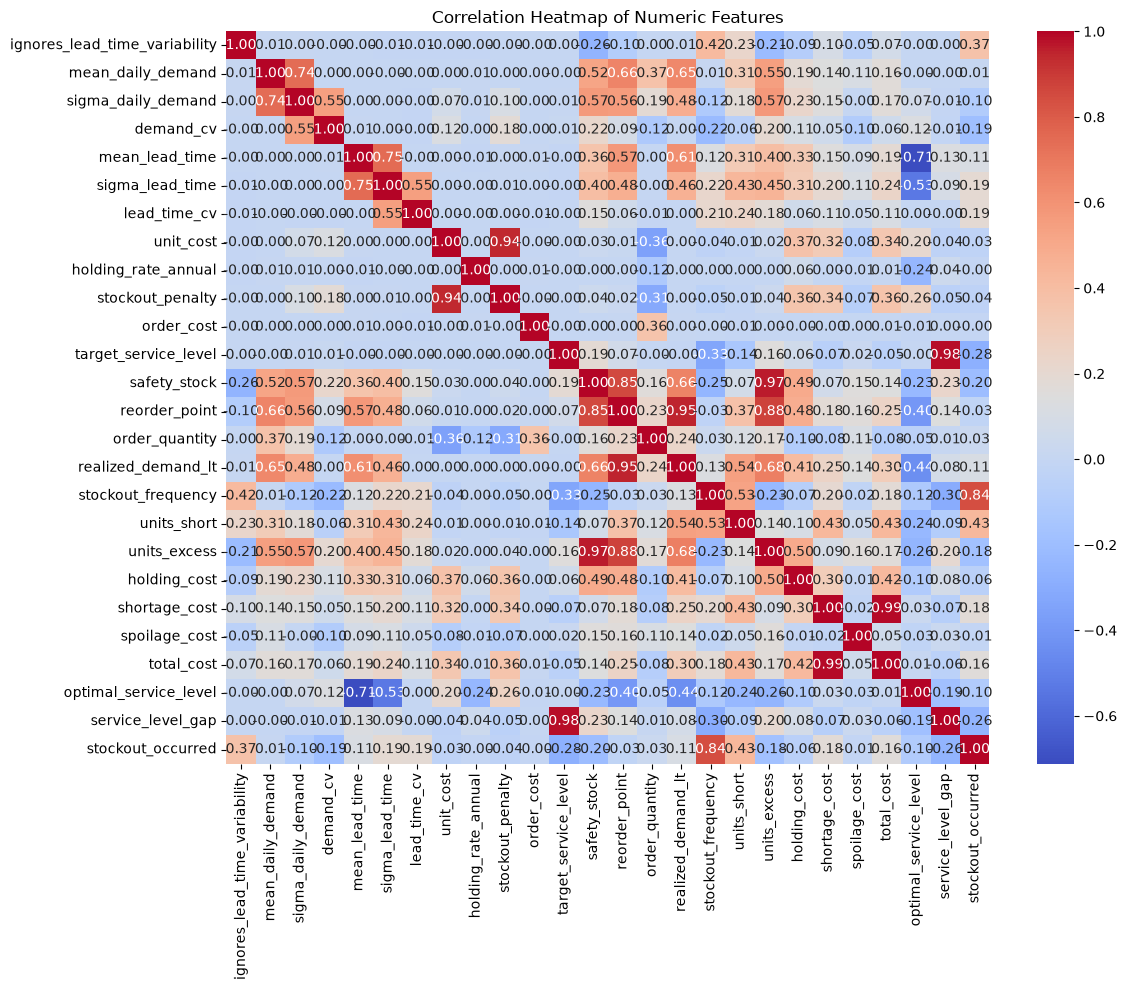

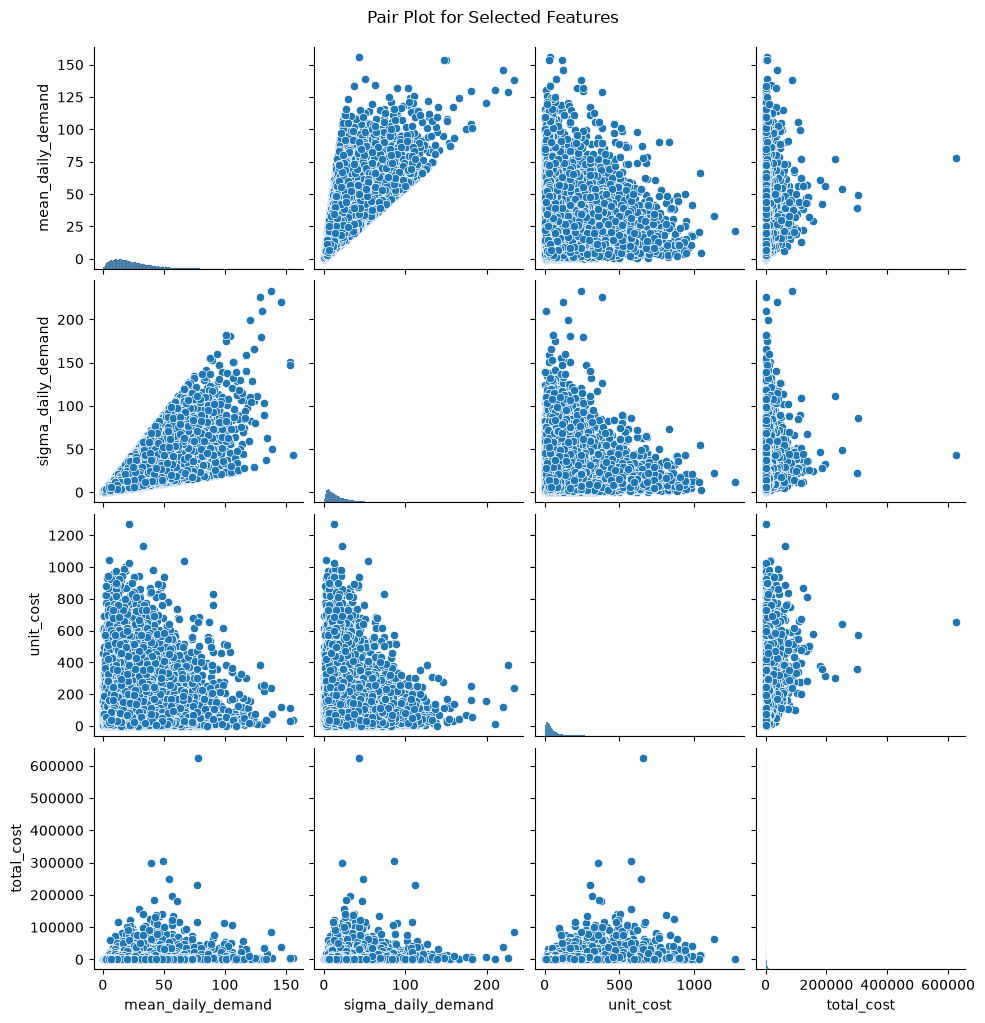

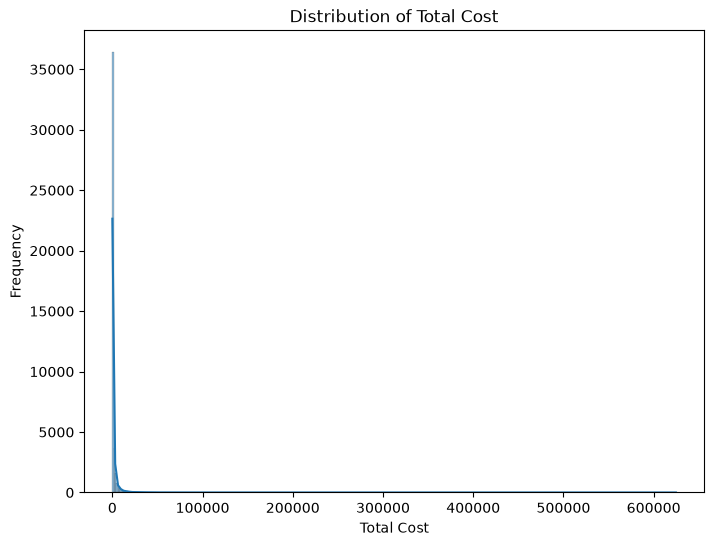

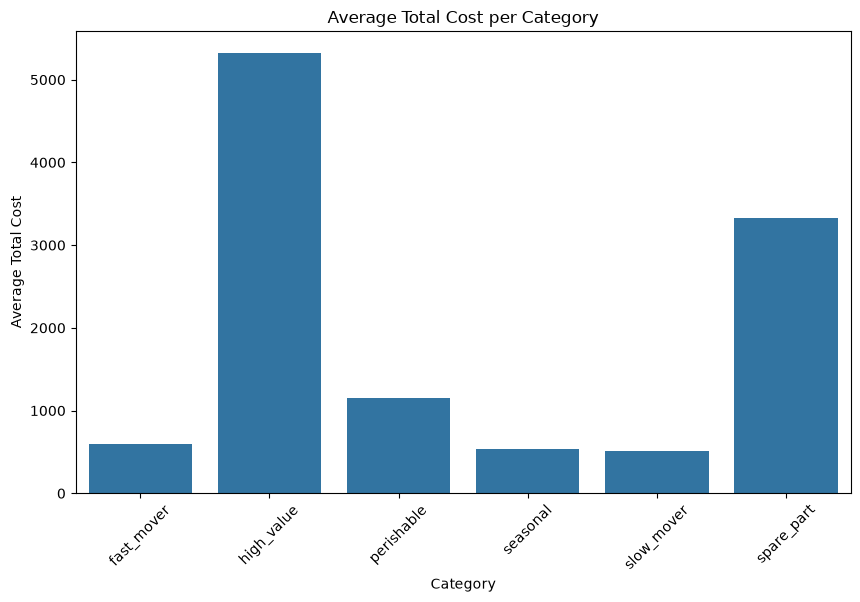

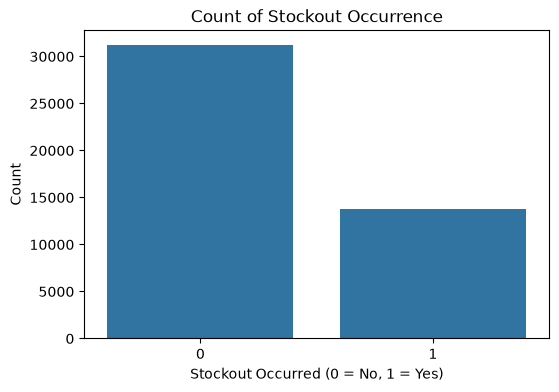

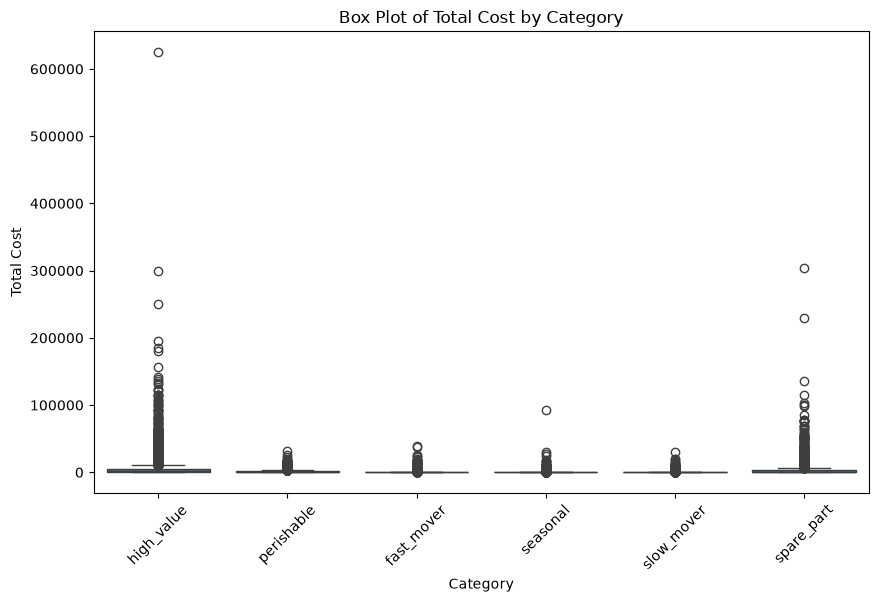

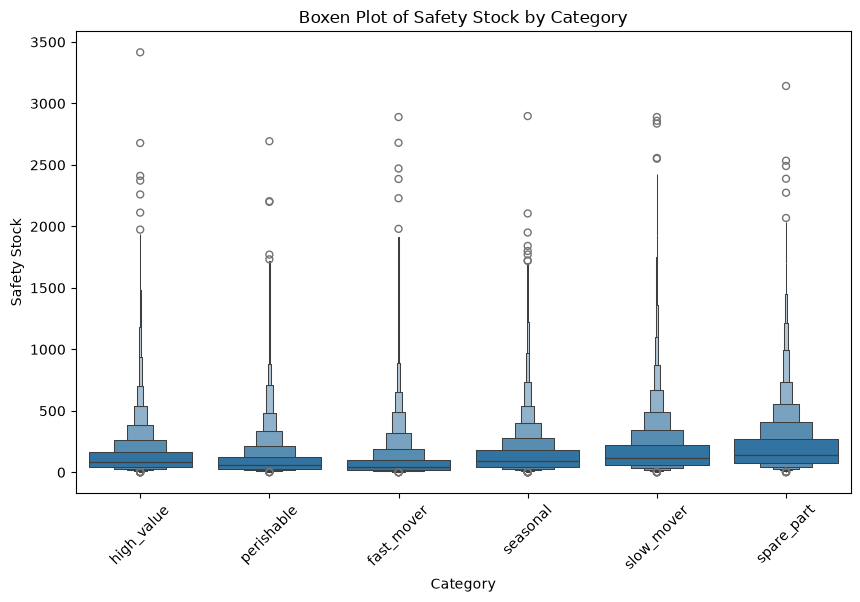

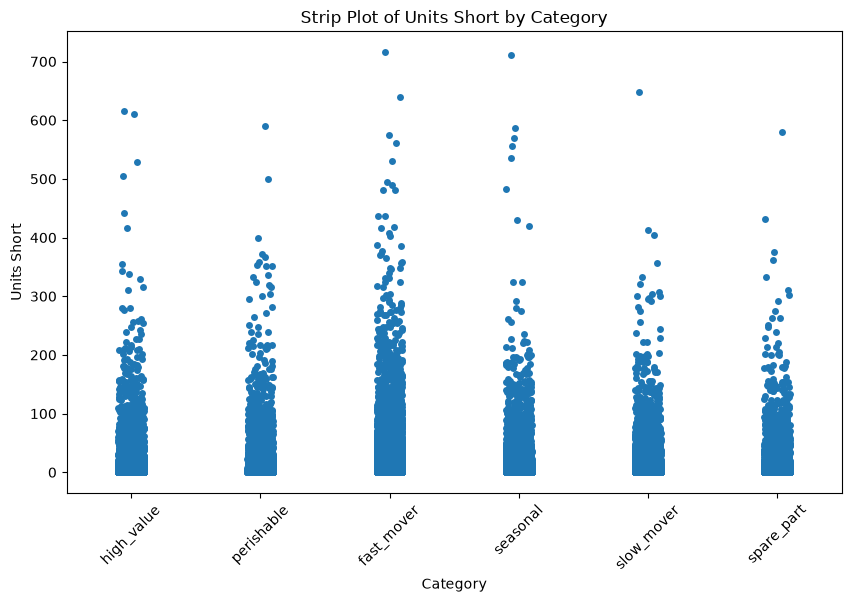

In [7]:
# Let's start our EDA with some descriptive statistics
print('Descriptive statistics for numerical columns:')
display(df.describe())

# Reduce the data frame to only numeric columns for correlation analysis

numeric_df = df.select_dtypes(include=[np.number])

# If there are four or more numeric columns, plot correlation heatmap
if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(12, 10))
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap of Numeric Features')
    plt.tight_layout()
    plt.show()
else:
    print('Not enough numeric columns for a correlation heatmap.')

# Pair Plot for selected features to observe relationships
selected_features = ['mean_daily_demand', 'sigma_daily_demand', 'unit_cost', 'total_cost']
if all(col in df.columns for col in selected_features):
    sns.pairplot(df[selected_features])
    plt.suptitle('Pair Plot for Selected Features', y=1.02)
    plt.show()
else:
    print('Some of the selected features for pair plot are missing.')

# Plot histogram for distribution of total_cost (if exists)
if 'total_cost' in df.columns:
    plt.figure(figsize=(8, 6))
    sns.histplot(df['total_cost'], kde=True)
    plt.title('Distribution of Total Cost')
    plt.xlabel('Total Cost')
    plt.ylabel('Frequency')
    plt.show()

# Bar Plot: Mean total cost per category
if 'category' in df.columns and 'total_cost' in df.columns:
    plt.figure(figsize=(10, 6))
    cat_cost = df.groupby('category')['total_cost'].mean().reset_index()
    sns.barplot(x='category', y='total_cost', data=cat_cost)
    plt.title('Average Total Cost per Category')
    plt.xlabel('Category')
    plt.ylabel('Average Total Cost')
    plt.xticks(rotation=45)
    plt.show()

# Count Plot (Pie Chart alternative) for Stockout Occurrence
if 'stockout_occurred' in df.columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(x='stockout_occurred', data=df)
    plt.title('Count of Stockout Occurrence')
    plt.xlabel('Stockout Occurred (0 = No, 1 = Yes)')
    plt.ylabel('Count')
    plt.show()

# Box Plot comparing total cost across categories
if 'category' in df.columns and 'total_cost' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='category', y='total_cost', data=df)
    plt.title('Box Plot of Total Cost by Category')
    plt.xlabel('Category')
    plt.ylabel('Total Cost')
    plt.xticks(rotation=45)
    plt.show()

# Boxen Plot for safety_stock per category if available
if 'category' in df.columns and 'safety_stock' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.boxenplot(x='category', y='safety_stock', data=df)
    plt.title('Boxen Plot of Safety Stock by Category')
    plt.xlabel('Category')
    plt.ylabel('Safety Stock')
    plt.xticks(rotation=45)
    plt.show()



# Strip Plot for units_short across categories
if 'category' in df.columns and 'units_short' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.stripplot(x='category', y='units_short', data=df, jitter=True)
    plt.title('Strip Plot of Units Short by Category')
    plt.xlabel('Category')
    plt.ylabel('Units Short')
    plt.xticks(rotation=45)
    plt.show()


# 2.0 Modeling & Prediction

In [8]:
def data_prep(df):
  # Define the target and features list
  target = 'stockout_occurred'

  # For simplicity, use a subset of numerical features as predictors
  feature_candidates = ['ignores_lead_time_variability', 'mean_daily_demand', 'sigma_daily_demand',
                        'mean_lead_time', 'sigma_lead_time', 'unit_cost', 'holding_rate_annual',
                        'stockout_penalty', 'order_cost', 'target_service_level']
    
  
    
  # Check the availability of these features
  features = [f for f in feature_candidates if f in df.columns]

  if target in df.columns and len(features) > 0:
      X = df[features]
      y = df[target]

  #Split the dataset
  X_full_train, X_val, y_full_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
  X_train, X_test, y_train, y_test = train_test_split(X_full_train, y_full_train, test_size=0.25, random_state=42)

  # Reset index
  X_train = X_train.reset_index(drop=True)
  X_val = X_val.reset_index(drop=True)
  X_test = X_test.reset_index(drop=True)  
  
  y_train = y_train.reset_index(drop=True)
  y_val = y_val.reset_index(drop=True)
  y_test = y_test.reset_index(drop=True)
  
  return X_train, y_train, X_val, y_val, X_test, y_test

In [9]:
X_train, y_train, X_val, y_val, X_test, y_test = data_prep(df)

X_train.shape, y_train.shape, X_val.shape, y_val.shape, X_test.shape, y_test.shape

((27000, 10), (27000,), (9000, 10), (9000,), (9000, 10), (9000,))

## xgboost

In [10]:
def train_xgboost_model(X_train, y_train, X_val, y_val, X_test, y_test, best_params=None):
    # Make copies to avoid modifying original dataframes in place
    X_train = X_train.copy()
    X_val = X_val.copy()
    X_test = X_test.copy()
    
    # Default robust parameters if no Optuna params are passed yet
    default_params = {
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'learning_rate': 0.03,
        'max_depth': 6,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'random_state': 42,
        'n_estimators': 1500
    }

    if best_params:
        default_params.update(best_params)

    # Initialize and train XGBoost with early stopping
    model = xgb.XGBClassifier(**default_params)

    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False)
        
    # Evaluate on Validation & Test Probabilities
    val_preds_proba = model.predict_proba(X_val)[:, 1]
    test_preds_proba = model.predict_proba(X_test)[:, 1]

    # Calculate ROC-AUC and PR-AUC directly using predicted probabilities
    val_auc = roc_auc_score(y_val, val_preds_proba)
    test_auc = roc_auc_score(y_test, test_preds_proba)

    val_pr_auc = average_precision_score(y_val, val_preds_proba)
    test_pr_auc = average_precision_score(y_test, test_preds_proba)

    print(f"Validation ROC-AUC: {val_auc:.4f} | PR-AUC: {val_pr_auc:.4f}")
    print(f"Test ROC-AUC:      {test_auc:.4f} | PR-AUC: {test_pr_auc:.4f}")
    
    return model, val_preds_proba, test_preds_proba

In [11]:
# 1. Fetch fresh data
X_train, y_train, X_val, y_val, X_test, y_test = data_prep(df)

# 2. Train XGBoost
xgb_model, xgb_val_preds_proba, xgb_test_preds_proba = train_xgboost_model(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test
)

Validation ROC-AUC: 0.8585 | PR-AUC: 0.7429
Test ROC-AUC:      0.8593 | PR-AUC: 0.7409


## Optuna tuning - best parameters

In [12]:
import warnings

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Define the file path
os.makedirs("params/model_params", exist_ok=True)
file_path = "params/model_params/xgb_params.json"

# Check if parameters already exist
if os.path.exists(file_path):
    print(f"Hyperparameters file found at {file_path}. Skipping tuning.")
    with open(file_path, "r") as f:
        xgb_params = json.load(f)
    print("Loaded Best Hyperparameters:", xgb_params)
else:
    print("No existing parameters found. Starting Optuna tuning...")
    
    # 1. Fetch fresh data
    X_train, y_train, X_val, y_val, X_test, y_test = data_prep(df)

    # Make copies to avoid modifying original dataframes in place
    X_train = X_train.copy()
    X_val = X_val.copy()
    X_test = X_test.copy()

    # 2. Define the Optuna objective function for XGBoost
    def objective(trial):
        params = {
            'n_estimators': 1500,  # High ceiling; early stopping handles stopping safely
            'max_depth': trial.suggest_int('max_depth', 3, 9),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
            'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
            'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
            'random_state': 42,
            'n_jobs': -1,
            'eval_metric': 'auc',
            'objective': 'binary:logistic',
            'early_stopping_rounds': 50  # Enabled early stopping
        }

        model = xgb.XGBClassifier(**params)

        # Train with early stopping using X_val
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        preds_proba = model.predict_proba(X_val)[:, 1]
        return roc_auc_score(y_val, preds_proba)

    # 3. Run the Optuna study
    xgb_study = optuna.create_study(direction='maximize')
    xgb_study.optimize(objective, n_trials=30)

    print(f'\nBest Validation ROC-AUC: {xgb_study.best_value:.4f}')
    print('Best Hyperparameters:', xgb_study.best_params)

    # 4. Save best parameters locally to JSON
    xgb_params = xgb_study.best_params

    with open(file_path, "w") as f:
        json.dump(xgb_params, f, indent=4)

    print(f"Best parameters saved successfully to {file_path}!")

Hyperparameters file found at params/model_params/xgb_params.json. Skipping tuning.
Loaded Best Hyperparameters: {'max_depth': 4, 'learning_rate': 0.0126054986646079, 'subsample': 0.8279256065639157, 'colsample_bytree': 0.9148182446507355, 'reg_alpha': 0.016689990458353506, 'reg_lambda': 6.862566108579105e-06, 'gamma': 0.15950142609451137, 'min_child_weight': 9}


Prediction with best params

In [13]:
# 1. Fetch fresh data
X_train, y_train, X_val, y_val, X_test, y_test = data_prep(df)


file_path = "params/model_params/xgb_params.json"
with open(file_path, "r") as f:
        xgb_params = json.load(f)

# 2. Train XGBoost
xgb_model, xgb_val_preds_proba, xgb_test_preds_proba = train_xgboost_model(
    X_train,
    y_train,
    X_val,
    y_val,
    X_test,
    y_test,
    best_params=xgb_params
    )

output_file = "model/xgb_model.bin" 
os.makedirs(os.path.dirname(output_file), exist_ok=True)

if os.path.exists(output_file):
    print(f"{output_file} already exists. Skipping save.")
else:
    with open(output_file, 'wb') as f_out: 
        pickle.dump(xgb_model, f_out)
    print(f"Saved model to {output_file}")

Validation ROC-AUC: 0.8687 | PR-AUC: 0.7584
Test ROC-AUC:      0.8685 | PR-AUC: 0.7578
Saved model to model/xgb_model.bin


Before tuning

- Validation ROC-AUC: 0.8585 | PR-AUC: 0.7429
- Test ROC-AUC:      0.8593 | PR-AUC: 0.7409

After tuning
- Validation ROC-AUC: 0.8687 | PR-AUC: 0.7584
- Test ROC-AUC:      0.8685 | PR-AUC: 0.7578
